# Titre
## 1. Introduction
(à rédiger)

### Chargement des bibliothèques et des fonctions

In [ ]:
# Import des modules
import pandas as pd
import matplotlib.pyplot as plt
import io
import json
import os
import time
from datetime import date
from pathlib import Path
import requests
from dotenv import load_dotenv, find_dotenv
import numpy as np
import seaborn as sns
import geopandas as gpd
import importlib

# Import des fonctions
from f_stat_desc import tracer_carte_meteo
from f_stat_desc import tracer_top_departements_meteo
from f_stat_desc import tracer_heatmap_meteo
import collecte_meteo
importlib.reload(collecte_meteo)
from collecte_meteo import recuperer_meteo

# Récupération des données
from chargement_sncf import charger_sncf
from chargement_gares import charger_gares

# Préparation des données SNCF
from preparation_sncf import (
    lister_gares,
    filtrer_liaisons_francaises,
    construire_correspondances,
    ajouter_departements
)

In [ ]:
# Chargement des bases de données
# Base de données climatologiques sortie de l'API
df = pd.read_csv(
    "meteo_mensuelle_2018_2026.csv", sep=';', encoding='utf-8',dtype={"departement": str}
)
# Base de données climatologiques enrichie des départements
df_meteo = pd.read_csv("data_meteo_enrichie.csv", sep=";")

# Base de données jointe (SNCF + Météo)
data = pd.read_csv("df_sncf_avec_meteo.csv")

# 2. Analyse de la régularité des TGV

## 2.1. Récupération et préparation des données SNCF


Les données ferroviaires proviennent du jeu de données *Régularité mensuelle TGV*, disponible sur la plateforme Open Data de la SNCF. Elles renseignent, pour chaque liaison et chaque mois, le nombre de trains prévus, les annulations et différents indicateurs de retard.

Afin d'automatiser la collecte et d'assurer la reproductibilité du projet, les données sont récupérées directement depuis l'API SNCF au moyen de requêtes HTTP, sans téléchargement manuel des fichiers. La période étudiée s'étend de **janvier 2018 à septembre 2026**.


In [2]:
# Récupération des données SNCF
df_sncf_brut = charger_sncf()

print("Dimensions de la base initiale :", df_sncf_brut.shape)
display(df_sncf_brut.head())

Dimensions de la base initiale : (12907, 26)


,date,service,gare_depart,gare_arrivee,duree_moyenne,nb_train_prevu,nb_annulation,commentaire_annulation,nb_train_depart_retard,retard_moyen_depart,...,nb_train_retard_sup_15,retard_moyen_trains_retard_sup15,nb_train_retard_sup_30,nb_train_retard_sup_60,prct_cause_externe,prct_cause_infra,prct_cause_gestion_trafic,prct_cause_materiel_roulant,prct_cause_gestion_gare,prct_cause_prise_en_charge_voyageurs
0,2018-01-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111
3,2018-01-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211,...,39,5.292211,18,8,33.333333,22.222222,16.666667,20.370370,5.555556,1.851852
4,2018-01-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784673,...,42,4.882372,10,0,15.789474,45.614035,19.298246,15.789474,1.754386,1.754386


### Exploration des gares

Avant de définir le périmètre géographique de notre étude, nous examinons les gares présentes dans la base initiale.

Cette exploration permet d'identifier les éventuelles gares étrangères, ainsi que les valeurs manquantes ou les appellations particulières qui pourraient nécessiter un traitement.

In [3]:
# Exploration des gares
gares = lister_gares(df_sncf_brut)

print("Nombre de gares distinctes :", len(gares))
print("\nListe des gares :")
print(gares)

# Analyse des valeurs manquantes
valeurs_manquantes = pd.DataFrame({
    "Nombre de valeurs manquantes": df_sncf_brut.isna().sum(),
    "Pourcentage (%)": df_sncf_brut.isna().mean() * 100
})

display(
    valeurs_manquantes
    .sort_values("Nombre de valeurs manquantes", ascending=False)
    .round(2)
)

Nombre de gares distinctes : 59

Liste des gares :
['AIX EN PROVENCE TGV', 'ANGERS SAINT LAUD', 'ANGOULEME', 'ANNECY', 'ARRAS', 'AVIGNON TGV', 'BARCELONA', 'BELLEGARDE (AIN)', 'BESANCON FRANCHE COMTE TGV', 'BORDEAUX ST JEAN', 'BREST', 'CHAMBERY CHALLES LES EAUX', 'DIJON VILLE', 'DOUAI', 'DUNKERQUE', 'FRANCFORT', 'GENEVE', 'GRENOBLE', 'ITALIE', 'LA ROCHELLE VILLE', 'LAUSANNE', 'LAVAL', 'LE CREUSOT MONTCEAU MONTCHANIN', 'LE MANS', 'LILLE', 'LYON PART DIEU', 'MACON LOCHE', 'MADRID', 'MARNE LA VALLEE', 'MARSEILLE ST CHARLES', 'METZ', 'MONTPELLIER', 'MULHOUSE VILLE', 'NANCY', 'NANTES', 'NICE VILLE', 'NIMES', 'PARIS EST', 'PARIS LYON', 'PARIS MONTPARNASSE', 'PARIS NORD', 'PARIS VAUGIRARD', 'PERPIGNAN', 'POITIERS', 'QUIMPER', 'REIMS', 'RENNES', 'SAINT ETIENNE CHATEAUCREUX', 'ST MALO', 'ST PIERRE DES CORPS', 'STRASBOURG', 'STUTTGART', 'TOULON', 'TOULOUSE MATABIAU', 'TOURCOING', 'TOURS', 'VALENCE ALIXAN TGV', 'VANNES', 'ZURICH']


,Nombre de valeurs manquantes,Pourcentage (%)
commentaire_annulation,12907,100.00
commentaire_retards_depart,12907,100.00
commentaires_retard_arrivee,12209,94.59
gare_depart,0,0.00
service,0,0.00
gare_arrivee,0,0.00
nb_train_prevu,0,0.00
nb_annulation,0,0.00
duree_moyenne,0,0.00
date,0,0.00


L'exploration de la base révèle **59 appellations de gares distinctes**, dont huit correspondent à des destinations étrangères. Concernant les valeurs manquantes, seules trois variables de commentaires sont concernées. Ces variables n'étant pas utilisées dans notre analyse, aucune imputation n'est nécessaire.

Afin de conserver un périmètre cohérent avec les données météorologiques françaises, nous excluons les liaisons dont la gare de départ ou d'arrivée se situe à l'étranger.

In [4]:
# Conservation des liaisons françaises
df_sncf_fr = filtrer_liaisons_francaises(df_sncf_brut)

print("Observations initiales :", len(df_sncf_brut))
print("Observations conservées :", len(df_sncf_fr))

Observations initiales : 12907
Observations conservées : 11357


## 2.2. Analyse descriptive de la régularité des TGV

### 2.2.1. Statistiques descriptives des données SNCF

Nous examinons les principales caractéristiques des liaisons ferroviaires : le nombre de trains prévus, les annulations, les retards à l'arrivée et la durée moyenne des trajets.


In [5]:
# Statistiques descriptives des principales variables SNCF
variables_desc = [
    "nb_train_prevu",
    "nb_annulation",
    "nb_train_retard_arrivee",
    "duree_moyenne"
]

stats_desc = df_sncf_fr[variables_desc].describe().T

display(stats_desc.round(2))

,count,mean,std,min,25%,50%,75%,max
nb_train_prevu,11357.0,294.73,185.05,0.0,177.0,249.0,401.0,1104.0
nb_annulation,11357.0,8.90,23.01,0.0,0.0,2.0,7.0,297.0
nb_train_retard_arrivee,11357.0,41.74,33.12,0.0,18.0,34.0,57.0,376.0
duree_moyenne,11357.0,157.53,76.27,0.0,97.0,144.0,202.0,786.0


Les statistiques descriptives mettent en évidence une forte hétérogénéité entre les observations. Les annulations présentent notamment une distribution asymétrique à droite : leur moyenne (8,90) est nettement supérieure à leur médiane (2), avec un maximum de 297 annulations.

Par ailleurs, certaines observations présentent une durée moyenne de trajet nulle, ce qui nécessite un contrôle de cohérence.

In [6]:
# Contrôle des durées moyennes nulles
durees_nulles = df_sncf_fr[df_sncf_fr["duree_moyenne"] == 0]

print("Nombre de durées nulles :", len(durees_nulles))

print(
    "Durées nulles avec aucun train prévu :",
    (durees_nulles["nb_train_prevu"] == 0).sum()
)

print(
    "Durées nulles avec des trains prévus :",
    (durees_nulles["nb_train_prevu"] > 0).sum()
)

# Aperçu des observations concernées
display(
    durees_nulles[
        ["date", "gare_depart", "gare_arrivee",
         "nb_train_prevu", "nb_annulation", "duree_moyenne"]
    ].head(5)
)

Nombre de durées nulles : 46
Durées nulles avec aucun train prévu : 46
Durées nulles avec des trains prévus : 0


,date,gare_depart,gare_arrivee,nb_train_prevu,nb_annulation,duree_moyenne
3406,2020-04-01,PARIS MONTPARNASSE,ST MALO,0,8,0
3407,2020-04-01,PARIS MONTPARNASSE,TOURS,0,9,0
3409,2020-04-01,NANTES,STRASBOURG,0,2,0
3411,2020-04-01,PARIS NORD,DOUAI,0,12,0
3412,2020-04-01,DUNKERQUE,PARIS NORD,0,15,0


Les 46 observations présentant une durée moyenne nulle correspondent toutes à des situations où aucun train n'était prévu. Ces valeurs ne doivent donc pas être interprétées comme des durées de trajet réelles. Nous les conserverons dans la base, mais elles seront exclues des calculs nécessitant des circulations effectives positives.

### Construction des indicateurs de retard

Afin d'étudier la régularité des TGV, nous commençons par calculer le nombre de **circulations effectives**, correspondant au nombre de trains prévus diminué du nombre de trains annulés.

Cet indicateur servira de dénominateur pour calculer le taux de retard à l'arrivée. Nous vérifions d'abord sa cohérence, notamment la présence de valeurs nulles ou négatives.

In [7]:
# Calcul des circulations effectives
df_sncf_analyse = df_sncf_fr.copy()

df_sncf_analyse["circulations_effectives"] = (
    df_sncf_analyse["nb_train_prevu"]
    - df_sncf_analyse["nb_annulation"]
)

# Contrôle des valeurs nulles ou négatives
print(
    "Circulations effectives nulles ou négatives :",
    (df_sncf_analyse["circulations_effectives"] <= 0).sum()
)

Circulations effectives nulles ou négatives : 46


Nous identifions **46 observations pour lesquelles le nombre de circulations effectives est négatif**. Ces observations, concentrées en avril et mai 2020, correspondent à des situations où aucun train n'était prévu, mais des annulations étaient néanmoins renseignées.

Le taux de retard ne pouvant pas être calculé lorsque le nombre de circulations effectives est nul ou négatif, nous choisissons de **ne pas tenir compte de ces observations dans le calcul des taux**, sans les supprimer de la base initiale.

In [8]:
# Calcul du taux de retard à l'arrivée (en %)
df_sncf_analyse["taux_retard_arrivee"] = (
    100 * df_sncf_analyse["nb_train_retard_arrivee"]
    / df_sncf_analyse["circulations_effectives"].where(
        df_sncf_analyse["circulations_effectives"] > 0
    )
)

# Statistiques descriptives
display(df_sncf_analyse["taux_retard_arrivee"].describe().round(2))

print(
    "Taux non calculables :",
    df_sncf_analyse["taux_retard_arrivee"].isna().sum()
)

count    11311.00
mean        14.75
std          7.83
min          0.00
25%          9.45
50%         13.33
75%         18.49
max        100.00
Name: taux_retard_arrivee, dtype: float64

Taux non calculables : 46


La moyenne des taux de retard s'élève à 14,75 %, avec une médiane de 13,33 %. Toutefois, cette moyenne accorde le même poids à chaque observation, indépendamment du nombre de trains concernés.

Nous calculons donc également un taux global de retard, en rapportant le nombre total de trains en retard au nombre total de circulations effectives.

In [9]:
# Conservation des observations avec des circulations effectives positives
df_valides = df_sncf_analyse[
    df_sncf_analyse["circulations_effectives"] > 0
]

# Calcul du taux global de retard
taux_global = (
    100 * df_valides["nb_train_retard_arrivee"].sum()
    / df_valides["circulations_effectives"].sum()
)

print(f"Taux global de retard à l'arrivée : {taux_global:.2f} %")

Taux global de retard à l'arrivée : 14.60 %


### Évolution annuelle du taux de retard

Afin d'étudier l'évolution de la régularité des TGV, nous calculons le taux global de retard pour chaque année. Les données de 2026 étant disponibles uniquement jusqu'en septembre, nous limitons la comparaison aux mois de janvier à septembre pour l'ensemble des années, afin de conserver des périodes comparables.

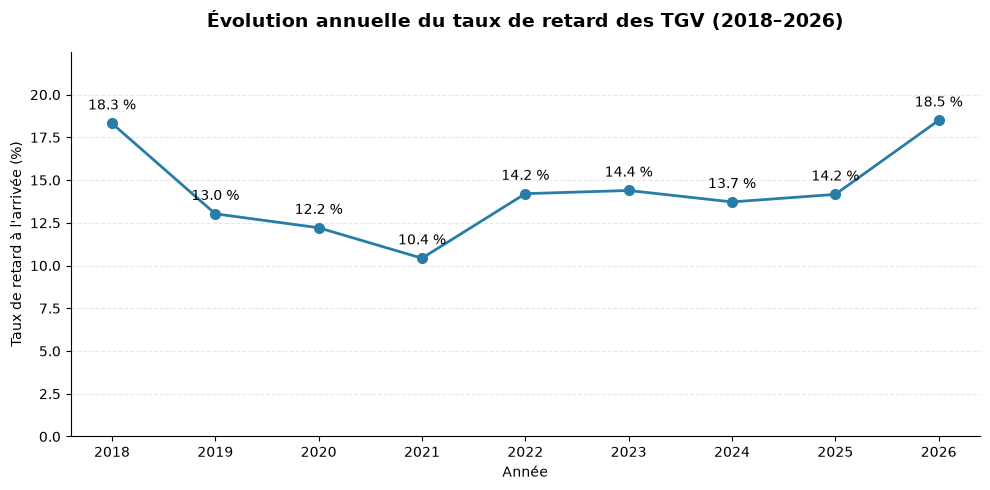

In [21]:
# Préparation des données pour la comparaison annuelle
df_annuel = df_valides.copy()

df_annuel["date"] = pd.to_datetime(df_annuel["date"])
df_annuel["annee"] = df_annuel["date"].dt.year
df_annuel["mois"] = df_annuel["date"].dt.month

# Comparaison de janvier à septembre pour toutes les années
df_annuel = df_annuel[df_annuel["mois"] <= 9]

# Calcul du taux global de retard par année
evolution_annuelle = df_annuel.groupby("annee")[
    ["nb_train_retard_arrivee", "circulations_effectives"]
].sum()

evolution_annuelle["taux_retard"] = (
    100 * evolution_annuelle["nb_train_retard_arrivee"]
    / evolution_annuelle["circulations_effectives"]
)

# Visualisation de l'évolution annuelle
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    evolution_annuelle.index,
    evolution_annuelle["taux_retard"],
    marker="o",
    linewidth=2,
    markersize=7,
    color="#287DA8"
)

# Affichage des pourcentages au-dessus des points
for annee, taux in evolution_annuelle["taux_retard"].items():
    ax.annotate(
        f"{taux:.1f} %",
        (annee, taux),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=10
    )

# Mise en forme
ax.set_title(
    "Évolution annuelle du taux de retard des TGV (2018–2026)",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Année")
ax.set_ylabel("Taux de retard à l'arrivée (%)")

ax.set_xticks(evolution_annuelle.index)
ax.set_ylim(0, evolution_annuelle["taux_retard"].max() + 4)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

for bordure in ["top", "right"]:
    ax.spines[bordure].set_visible(False)

plt.tight_layout()
plt.show()

Le taux de retard à l'arrivée diminue entre 2018 et 2021, passant de **18,32 % à 10,43 %**. Il augmente ensuite et se stabilise autour de 14 % entre 2022 et 2025, avant d'atteindre **18,49 % en 2026**, son niveau le plus élevé sur la période étudiée.

Ces variations montrent que la régularité des TGV évolue sensiblement au cours du temps, sans permettre à ce stade d'en identifier les causes.

### Saisonnalité des retards

Nous étudions maintenant l'évolution du taux de retard selon le mois de l'année, afin d'identifier d'éventuelles variations saisonnières.

Pour cette analyse, nous retenons les années complètes de 2018 à 2025, afin que chaque mois soit observé sur le même nombre d'années.

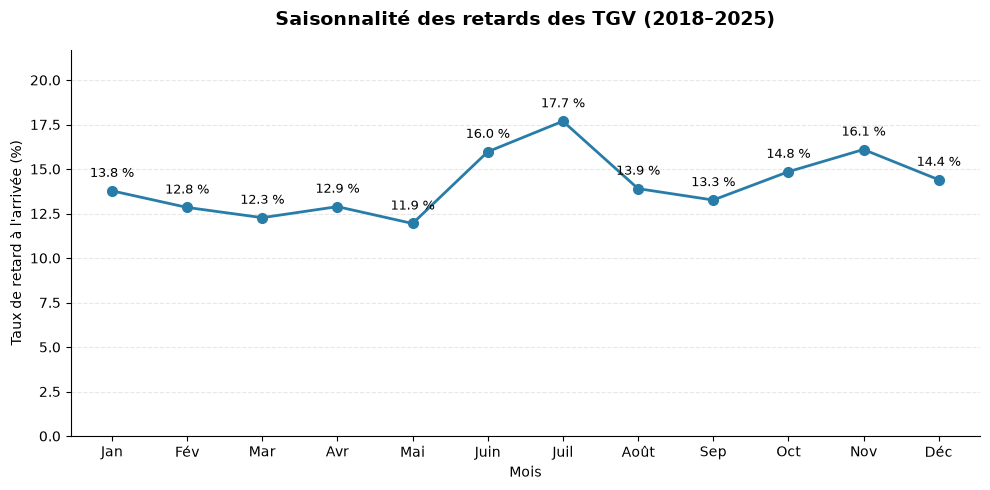

In [22]:
# Préparation des données pour l'analyse de la saisonnalité
df_mensuel = df_valides.copy()

df_mensuel["date"] = pd.to_datetime(df_mensuel["date"])

# Conservation des années complètes (2018–2025)
df_mensuel = df_mensuel[df_mensuel["date"].dt.year <= 2025]
df_mensuel["mois"] = df_mensuel["date"].dt.month

# Calcul du taux global de retard par mois
evolution_mensuelle = df_mensuel.groupby("mois")[
    ["nb_train_retard_arrivee", "circulations_effectives"]
].sum()

evolution_mensuelle["taux_retard"] = (
    100 * evolution_mensuelle["nb_train_retard_arrivee"]
    / evolution_mensuelle["circulations_effectives"]
)

# Noms des mois
mois_noms = [
    "Jan", "Fév", "Mar", "Avr", "Mai", "Juin",
    "Juil", "Août", "Sep", "Oct", "Nov", "Déc"
]

# Visualisation de la saisonnalité
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    evolution_mensuelle.index,
    evolution_mensuelle["taux_retard"],
    marker="o",
    linewidth=2,
    markersize=7,
    color="#287DA8"
)

# Affichage des pourcentages au-dessus des points
for mois, taux in evolution_mensuelle["taux_retard"].items():
    ax.annotate(
        f"{taux:.1f} %",
        (mois, taux),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=9
    )

# Mise en forme
ax.set_title(
    "Saisonnalité des retards des TGV (2018–2025)",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Mois")
ax.set_ylabel("Taux de retard à l'arrivée (%)")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(mois_noms)

ax.set_ylim(0, evolution_mensuelle["taux_retard"].max() + 4)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

for bordure in ["top", "right"]:
    ax.spines[bordure].set_visible(False)

plt.tight_layout()
plt.show()

Le taux de retard varie selon les mois de l'année. Sur la période 2018–2025, il est particulièrement élevé en **juillet (17,69 %)** et en **novembre (16,10 %)**, tandis que **mai présente le taux le plus faible (11,94 %)**.

Ces différences suggèrent l'existence de variations saisonnières, sans permettre d'en identifier les causes. Nous chercherons notamment à déterminer si certaines de ces variations sont associées aux conditions météorologiques.

### Analyse des causes des retards

Après avoir étudié l'évolution temporelle des retards, nous nous intéressons à leurs causes. La SNCF distingue six catégories, notamment les problèmes d'infrastructure, de matériel roulant, de gestion du trafic et les causes externes.

Cette dernière catégorie comprend les événements météorologiques, mais également d'autres perturbations. Elle ne permet donc pas d'isoler précisément le rôle de la météo, ce qui motive l'enrichissement de notre base par les données de Météo-France.

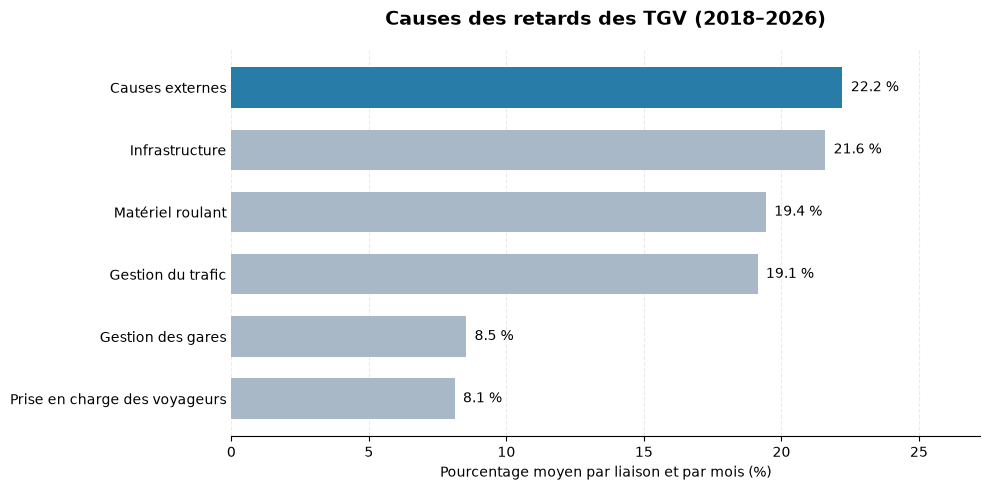

In [17]:
# Variables relatives aux causes des retards
variables_causes = [
    "prct_cause_externe",
    "prct_cause_infra",
    "prct_cause_gestion_trafic",
    "prct_cause_materiel_roulant",
    "prct_cause_gestion_gare",
    "prct_cause_prise_en_charge_voyageurs"
]

# Noms des catégories
noms_causes = {
    "prct_cause_externe": "Causes externes",
    "prct_cause_infra": "Infrastructure",
    "prct_cause_gestion_trafic": "Gestion du trafic",
    "prct_cause_materiel_roulant": "Matériel roulant",
    "prct_cause_gestion_gare": "Gestion des gares",
    "prct_cause_prise_en_charge_voyageurs": "Prise en charge des voyageurs"
}

# Moyenne des pourcentages par catégorie
causes_moyennes = (
    df_sncf_fr[variables_causes]
    .mean()
    .rename(index=noms_causes)
    .sort_values()
)

# Création du graphique
fig, ax = plt.subplots(figsize=(10, 5))

# Mise en évidence des causes externes
couleurs = [
    "#287DA8" if cause == "Causes externes" else "#A8B8C7"
    for cause in causes_moyennes.index
]

barres = ax.barh(
    causes_moyennes.index,
    causes_moyennes.values,
    color=couleurs,
    height=0.65
)

# Affichage des pourcentages sur les barres
ax.bar_label(
    barres,
    labels=[f"{val:.1f} %" for val in causes_moyennes.values],
    padding=6,
    fontsize=10
)

# Mise en forme
ax.set_title(
    "Causes des retards des TGV (2018–2026)",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Pourcentage moyen par liaison et par mois (%)")
ax.set_xlim(0, causes_moyennes.max() + 5)

ax.xaxis.grid(True, linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

# Suppression des bordures inutiles
for bordure in ["top", "right", "left"]:
    ax.spines[bordure].set_visible(False)

ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.show()

Les causes externes figurent parmi les catégories les plus représentées. Cependant, cette catégorie regroupe différentes perturbations et ne permet pas d'isoler celles liées aux conditions météorologiques.

Nous complétons donc notre analyse avec les données de Météo-France afin d'étudier plus précisément les associations entre météo et retards des TGV.

# 3. Intégration des données météorologiques

## 3.1. Identification des départements des gares SNCF

Afin de rapprocher les retards des TGV des conditions météorologiques, nous devons identifier les départements de départ et d'arrivée de chaque liaison.

Cette information n'étant pas directement disponible dans la base de régularité SNCF, nous avons choisi **d'automatiser son identification plutôt que de renseigner manuellement les départements**. Pour cela, nous récupérons un second jeu de données géographiques des gares, contenant notamment leurs noms et leurs codes INSEE.

L'objectif est de mettre en correspondance les gares des deux sources afin d'en déduire leurs départements. Cette opération nécessite également une harmonisation des noms et le traitement de quelques cas particuliers.

In [18]:
# Récupération de la base géographique des gares SNCF
df_gares = charger_gares()

print("Dimensions de la base géographique :", df_gares.shape)

# Aperçu des informations utiles à notre correspondance
display(df_gares[["nom", "codeinsee"]].head())

Dimensions de la base géographique : (2792, 7)


,nom,codeinsee
0,Abancourt,60001
1,Abbaretz,44001
2,Abbeville,80001
3,Ablon-sur-Seine,94001
4,Achères Grand Cormier,78551


Les noms des gares ne sont pas toujours identiques dans les deux bases. Afin d'automatiser leur mise en correspondance, nous normalisons les appellations en harmonisant les majuscules, les accents, la ponctuation et certaines abréviations.

Pour les gares dont les appellations restent différentes, nous utilisons des correspondances spécifiques préalablement vérifiées. Enfin, trois cas particuliers (*LILLE*, *MONTPELLIER* et *PARIS VAUGIRARD*) nécessitent une attribution directe du département, sans identifier arbitrairement une gare précise.

Les codes INSEE permettent ensuite d'extraire les départements associés aux gares.

In [19]:
# Construction de la table de correspondance gare-département
table_correspondances = construire_correspondances(
    df_sncf_fr, df_gares
)

print("Nombre de gares identifiées :", len(table_correspondances))

# Répartition des méthodes de correspondance
print("\nMéthodes utilisées :")
display(table_correspondances["methode"].value_counts())

# Aperçu de la table obtenue
display(
    table_correspondances[
        ["gare_sncf", "nom_geo", "departement", "methode"]
    ].head(10)
)

Nombre de gares identifiées : 51

Méthodes utilisées :


methode
Normalisation automatique    37
Appellation corrigée         11
Département uniquement        3
Name: count, dtype: int64

,gare_sncf,nom_geo,departement,methode
0,AIX EN PROVENCE TGV,Aix-en-Provence TGV,13,Normalisation automatique
1,ANGERS SAINT LAUD,Angers Saint-Laud,49,Normalisation automatique
2,ANGOULEME,Angoulême,16,Normalisation automatique
3,ANNECY,Annecy,74,Normalisation automatique
4,ARRAS,Arras,62,Normalisation automatique
5,AVIGNON TGV,Avignon TGV,84,Normalisation automatique
6,BELLEGARDE (AIN),Bellegarde-sur-Valserine,01,Appellation corrigée
7,BESANCON FRANCHE COMTE TGV,Besançon Franche-Comté TGV,25,Normalisation automatique
8,BORDEAUX ST JEAN,Bordeaux Saint-Jean,33,Normalisation automatique
9,BREST,Brest,29,Normalisation automatique


La mise en correspondance permet d'identifier les départements des 51 gares françaises : 37 par normalisation automatique, 11 grâce à des corrections d'appellation et 3 par attribution directe du département.

Nous utilisons cette table pour enrichir la base de régularité SNCF avec les départements de départ et d'arrivée.

In [20]:
# Ajout des départements de départ et d'arrivée
df_sncf_enrichi = ajouter_departements(
    df_sncf_fr, table_correspondances
)

# Contrôle du résultat
print("Dimensions avant :", df_sncf_fr.shape)
print("Dimensions après :", df_sncf_enrichi.shape)

print("\nDépartements manquants :")
print(df_sncf_enrichi[["dep_depart", "dep_arrivee"]].isna().sum())

# Aperçu des nouvelles colonnes
display(
    df_sncf_enrichi[
        ["gare_depart", "dep_depart", "gare_arrivee", "dep_arrivee"]
    ].head()
)

Dimensions avant : (11357, 26)
Dimensions après : (11357, 28)

Départements manquants :
dep_depart     0
dep_arrivee    0
dtype: int64


,gare_depart,dep_depart,gare_arrivee,dep_arrivee
0,BORDEAUX ST JEAN,33,PARIS MONTPARNASSE,75
1,LE MANS,72,PARIS MONTPARNASSE,75
2,PARIS MONTPARNASSE,75,LA ROCHELLE VILLE,17
3,PARIS MONTPARNASSE,75,NANTES,44
4,POITIERS,86,PARIS MONTPARNASSE,75


# 4. Analyse des données climatologiques

## 4.1. Collecte automatisée des données climatologiques via l'API Météo-France (DPClim)


1. Justification de l'échelle mensuelle
Avant d'extraire les données de Météo-France, le choix de la granularité temporelle (quotidienne, décadaire ou mensuelle) a été guidé par deux considérations :

Cohérence méthodologique : L'impact des aléas climatiques sur l'exploitation ferroviaire ne se limite pas au seul jour de l'événement (inertie des sols, saturation hydrique, dégradation progressive des infrastructures). L'agrégation mensuelle permet de capter ces effets cumulés et de s'aligner directement avec la maille temporelle des indicateurs de régularité SNCF.

Contrainte technique : Le volume de données et les limitations de débit de l'API publique rendent l'extraction mensuelle nettement plus soutenable sur l'ensemble du territoire français et sur une période de près de neuf ans (2018–2026).

2. Architecture du pipeline d'extraction
L'API publique de Météo-France fonctionnant de manière asynchrone et limitant chaque commande à une année par station, le script suivant automatise la collecte sur l'ensemble des départements métropolitains et ultramarins en quatre étapes :

Recensement et filtrage des stations : Pour chaque département, le script interroge la liste des postes publics (postePublic), puis consulte leurs métadonnées (information-station) afin de vérifier leur période d'activité. Seules les stations actives sur tout ou partie de la fenêtre 2018–2026 sont retenues, et les requêtes sont restreintes à leurs années réelles d'ouverture.

Commande asynchrone et récupération (polling) : Les données mensuelles sont commandées année par année (commande-station/mensuelle), puis le script interroge périodiquement le serveur (commande/fichier) jusqu'à ce que le fichier CSV soit généré (statut HTTP 200/201).

Gestion des quotas et reprise sur interruption : Le volume global des requêtes nécessitant près de 72 heures d'exécution, le pipeline intègre une régulation du débit (MIN_INTERVAL et gestion des erreurs 429) ainsi qu'un système de cache local (cache_meteo/ et cache_info/). Chaque station traitée étant sauvegardée individuellement, le script peut être interrompu et relancé à tout moment sans perdre la progression déjà effectuée.

Consolidation finale : Une fois la collecte achevée, l'ensemble des fichiers stations non vides est fusionné et dédoublonné au sein d'une table unique (meteo_mensuelle_2018_2026.csv), prête pour les étapes de nettoyage et d'enrichissement.

In [ ]:
import importlib
import collecte_meteo
importlib.reload(collecte_meteo)

# Appel de la fonction
df_meteo = collecte_meteo.recuperer_meteo(
    annee_debut=2018,
    annee_fin=2026,
)

# Aperçu du résultat
print("Dimensions :", df_meteo.shape)
df_meteo.head()

## 4.2 Enrichissement géographique et libellés des départements

Afin de faciliter l'interprétation des résultats et les futures analyses spatiales, cette étape associe chaque code départemental déjà présent dans le jeu de données issu de l'API Météo-France à son nom officiel :

Chargement typé des données : Lors de l'importation du fichier CSV, la colonne departement est forcée au format texte (dtype={"departement": str}) afin de préserver l'intégrité des codes géographiques et d'éviter toute conversion numérique implicite.

Création du libellé départemental (NOM_DEP) : À partir d'un dictionnaire de référence couvrant la France métropolitaine et les collectivités d'outre-mer, chaque code est mappé vers son nom complet. L'instruction .fillna('Non répertorié') permet de gérer proprement d'éventuels codes absents du référentiel sans interrompre l'exécution.

Sauvegarde intermédiaire : La table enrichie est ensuite enregistrée (data_meteo_enrichie.csv) pour servir de base aux étapes suivantes de filtrage qualité et d'agrégation.

In [9]:
df = pd.read_csv(
    "meteo_mensuelle_2018_2026.csv", sep=';', encoding='utf-8',dtype={"departement": str}
)

# Dictionnaire de correspondance
correspondance = {
    '1': 'Ain',
    '2': 'Aisne',
    '3': 'Allier',
    '4': 'Alpes-de-Haute-Provence',
    '5': 'Hautes-Alpes',
    '6': 'Alpes-Maritimes',
    '7': 'Ardèche',
    '8': 'Ardennes',
    '9': 'Ariège',
    '10': 'Aube',
    '11': 'Aude',
    '12': 'Aveyron',
    '13': 'Bouches-du-Rhône',
    '14': 'Calvados',
    '15': 'Cantal',
    '16': 'Charente',
    '17': 'Charente-Maritime',
    '18': 'Cher',
    '19': 'Corrèze',
    '20': 'Corse',
    '21': "Côte-d'Or",
    '22': "Côtes-d'Armor",
    '23': 'Creuse',
    '24': 'Dordogne',
    '25': 'Doubs',
    '26': 'Drôme',
    '27': 'Eure',
    '28': 'Eure-et-Loir',
    '29': 'Finistère',
    '30': 'Gard',
    '31': 'Haute-Garonne',
    '32': 'Gers',
    '33': 'Gironde',
    '34': 'Hérault',
    '35': 'Ille-et-Vilaine',
    '36': 'Indre',
    '37': 'Indre-et-Loire',
    '38': 'Isère',
    '39': 'Jura',
    '40': 'Landes',
    '41': 'Loir-et-Cher',
    '42': 'Loire',
    '43': 'Haute-Loire',
    '44': 'Loire-Atlantique',
    '45': 'Loiret',
    '46': 'Lot',
    '47': 'Lot-et-Garonne',
    '48': 'Lozère',
    '49': 'Maine-et-Loire',
    '50': 'Manche',
    '51': 'Marne',
    '52': 'Haute-Marne',
    '53': 'Mayenne',
    '54': 'Meurthe-et-Moselle',
    '55': 'Meuse',
    '56': 'Morbihan',
    '57': 'Moselle',
    '58': 'Nièvre',
    '59': 'Nord',
    '60': 'Oise',
    '61': 'Orne',
    '62': 'Pas-de-Calais',
    '63': 'Puy-de-Dôme',
    '64': 'Pyrénées-Atlantiques',
    '65': 'Hautes-Pyrénées',
    '66': 'Pyrénées-Orientales',
    '67': 'Bas-Rhin',
    '68': 'Haut-Rhin',
    '69': 'Rhône',
    '70': 'Haute-Saône',
    '71': 'Saône-et-Loire',
    '72': 'Sarthe',
    '73': 'Savoie',
    '74': 'Haute-Savoie',
    '75': 'Paris',
    '76': 'Seine-Maritime',
    '77': 'Seine-et-Marne',
    '78': 'Yvelines',
    '79': 'Deux-Sèvres',
    '80': 'Somme',
    '81': 'Tarn',
    '82': 'Tarn-et-Garonne',
    '83': 'Var',
    '84': 'Vaucluse',
    '85': 'Vendée',
    '86': 'Vienne',
    '87': 'Haute-Vienne',
    '88': 'Vosges',
    '89': 'Yonne',
    '90': 'Territoire de Belfort',
    '91': 'Essonne',
    '92': 'Hauts-de-Seine',
    '93': 'Seine-Saint-Denis',
    '94': 'Val-de-Marne',
    '95': "Val-d'Oise",
    '971': 'Guadeloupe',
    '972': 'Martinique',
    '973': 'Guyane',
    '974': 'La Réunion',
    '975': 'Saint-Pierre-et-Miquelon',
    '984': 'Terres australes et antarctiques françaises',
    '985': 'Mayotte',
    '986': 'Wallis-et-Futuna',
    '987': 'Polynésie française',
    '988': 'Nouvelle-Calédonie',
}

# 4. Création de la colonne NOM_DEP via le dictionnaire
df['NOM_DEP'] = df['departement'].map(correspondance).fillna('Non répertorié')

# Aperçu du résultat
print(df[['POSTE', 'departement', 'NOM_DEP']].head(20))

# ==========================================
# Sauvegarde de la base finale
# ==========================================
df.to_csv('data_meteo_enrichie.csv', index=False,sep=';')
print(f'Nombre de lignes après filtrage : {len(df)}')


      POSTE departement NOM_DEP
0   1014002           1     Ain
1   1014002           1     Ain
2   1014002           1     Ain
3   1014002           1     Ain
4   1014002           1     Ain
5   1014002           1     Ain
6   1014002           1     Ain
7   1014002           1     Ain
8   1014002           1     Ain
9   1014002           1     Ain
10  1014002           1     Ain
11  1014002           1     Ain
12  1014002           1     Ain
13  1014002           1     Ain
14  1014002           1     Ain
15  1014002           1     Ain
16  1014002           1     Ain
17  1014002           1     Ain
18  1014002           1     Ain
19  1014002           1     Ain
Nombre de lignes après filtrage : 357361


## 4.3 Contrôle qualité, sélection des variables et agrégation départementale

Les relevés bruts de Météo-France contiennent plusieurs dizaines de stations météorologiques par département, avec un niveau de fiabilité variable selon les capteurs et les périodes. Afin de garantir une correspondance unique (département, mois) avec les données SNCF tout en préservant la qualité de l'information, nous appliquons le traitement suivant en quatre étapes :

Filtrage par indice de qualité : Météo-France associe aux mesures principales un code qualité (0 : donnée protégée validée définitivement par le climatologue, 1 : donnée validée par un controle automatique ou un climatologue, 9 : donnée filtrée par contrôle automatique, 2 : donnée douteuse). Plutôt que de supprimer des lignes entières et de perdre des observations valides sur d'autres capteurs, nous remplaçons uniquement les mesures douteuses (code == 2) par des valeurs manquantes (NaN) pour les variables concernées (RR, TN, TX, TAMPLIM). 

Sélection des variables d'intérêt : Nous restreignons le jeu de données aux clés de jointure (departement, DATE) ainsi qu'aux indicateurs météorologiques susceptibles d'impacter le trafic ferroviaire (gel, neige, précipitations cumulées et fortes pluies, orages, brouillard, vents violents, fortes chaleurs et amplitude thermique).

Agrégation spatiale par département : Les relevés sont ensuite agrégés par moyenne mensuelle au niveau départemental (groupby(['departement', 'DATE'])). L'utilisation préalable des NaN permet à pandas d'ignorer automatiquement les mesures invalidées lors du calcul de la moyenne, sans biaiser les résultats.

Normalisation des fréquences mensuelles : Enfin, les variables de comptage d'événements (nombre de jours de gel, d'orage, de forte chaleur, etc.) sont converties en pourcentage de jours dans le mois. Cette normalisation neutralise le biais lié à la durée variable des mois (28 à 31 jours) et rend les observations comparables sur l'ensemble de l'année.

In [25]:
# Trie de variables : On ne garde que les observations qualitatives (0,1 ou 9)
# Prise en compte de la qualité (si la qualité est >= 2, on met la valeur à NaN)
# Mettre la valeur à NaN ne gènera pas Pandas plus tard et permet de garder des données de qualité pour l'aggrégation
# Pour les précipitations
if 'QRR' in df_meteo.columns:
    df_meteo.loc[pd.to_numeric(df_meteo['QRR'], errors='coerce') == 2, 'RR'] = np.nan

# Pour la température minimale
if 'QTN' in df_meteo.columns:
    df_meteo.loc[pd.to_numeric(df_meteo['QTN'], errors='coerce') == 2, 'TN'] = np.nan

# Pour la température maximale
if 'QTX' in df_meteo.columns:
    df_meteo.loc[pd.to_numeric(df_meteo['QTX'], errors='coerce') == 2, 'TX'] = np.nan

# Pour l'amplitude thermique
if 'QTAMPLIM' in df_meteo.columns:
    df_meteo.loc[pd.to_numeric(df_meteo['QTAMPLIM'], errors='coerce') == 2, 'TAMPLIM'] = np.nan


#  Sélection des variables à conserver (clés de jointure + variables cibles)
variables_utiles = [
    'departement',
    'NOM_DEP',
    'DATE',

    # Froid, neige et minimales
    'NBJGELEE', # Nombre de jours de gel (TN≤0"°C" )
    'NBJSOLNG', # Nombre de jours avec sol enneigé
    'TN', # Moyenne mensuelle des températures minimales quotidiennes

    # Pluie, orages et brouillard
    'RR', # Cumul mensuel des précipitations (en mm)
    'NBJRR10', # Nombre de jours de fortes pluies (>= 10mm)
    'NBJORAG', # Nombre de jours d'orage dans le mois
    'NBJBROU', # Nombre de jours de brouillard dans le mois
    # Vent
    'NBJFF16', # Nombre de jours avec vent moyen dépassant 16 m/s

    # Chaleur et maximales
    'TX', # Moyenne mensuelle des températures maximales quotidiennes
    'NBJTX30', # Nombre de jours de chaleur (TX≥30"°C" )

    # Amplitude thermique
    'TAMPLIM' # Amplitude thermique moyenne du mois
]

# Filtrage du DataFrame
df_meteo = df_meteo[variables_utiles]

# Calcule de la moyenne de toutes les colonnes numériques par département et par mois
# numeric_only=True évite d'essayer de faire la moyenne sur le nom des stations (texte)
df_meteo = df_meteo.groupby(['departement','NOM_DEP', 'DATE']).mean(numeric_only=True).reset_index()

# Transforme la colonne DATE en objet Period pour récupérer les jours du mois
df_meteo['nb_jours_mois'] = pd.to_datetime(df_meteo['DATE'].astype(str), format='%Y%m').dt.days_in_month

# Transformer les compteurs de phénomène en pourcentages de jours par mois
colonnes_comptage = ['NBJGELEE', 'NBJSOLNG', 'NBJRR10', 'NBJORAG', 'NBJBROU','NBJFF16', 'NBJTX30']

for col in colonnes_comptage:
    df_meteo[col] = (df_meteo[col] / df_meteo['nb_jours_mois']) * 100
df_meteo = df_meteo.drop(columns=['nb_jours_mois']) # On se débarasse de la colonne une fois sa mission remplie


## 4.4 Création des indicateurs d'anomalie climatique

L'objectif de cette étape est de contextualiser les relevés météorologiques bruts afin d'en faciliter l'interprétation analytique. En effet, une valeur absolue de température ou de précipitations ne permet pas, à elle seule, d'évaluer le caractère exceptionnel d'un événement climatique : une même température peut être tout à fait normale en été mais extrême en hiver, ou varier fortement selon les régions.

Pour mesurer cet écart à la normale saisonnière (variables *_ME de Météo-France), nous avons construit trois indicateurs d'anomalie :

anomalie_rr_pct : l'écart relatif (en %) du cumul de précipitations par rapport à la normale climatologique du mois, en sécurisant le calcul lorsque la normale est nulle (RR_ME == 0) afin d'éviter toute division par zéro.

anomalie_tn et anomalie_tx : l'écart absolu (en °C) des températures minimales et maximales moyennes par rapport aux normales saisonnières attendues.

Ces variables permettent d'isoler plus finement les épisodes météorologiques atypiques ou extrêmes (vagues de chaleur, épisodes de gel tardif, précipitations excédentaires) susceptibles de dépasser les seuils de tolérance opérationnelle des infrastructures et du matériel ferroviaire de la SNCF.

In [26]:
# Extraction du mois (1 à 12) pour calculer les normales saisonnières par département
df_meteo['mois'] = df_meteo['DATE'] % 100

RR_ME = df_meteo.groupby(['departement', 'mois'])['RR'].transform('mean')
TN_ME = df_meteo.groupby(['departement', 'mois'])['TN'].transform('mean')
TX_ME = df_meteo.groupby(['departement', 'mois'])['TX'].transform('mean')

# Calcul des anomalies climatiques
# Pluie : écart relatif (%) lorsque la normale est >= 5 mm (évite les ratios explosifs en saison sèche)
# Plafonnement à +300 % pour limiter l'impact des valeurs extrêmes isolées
df_meteo['anomalie_rr_pct'] = np.where(
    RR_ME >= 5,
    ((df_meteo['RR'] - RR_ME) / RR_ME) * 100,
    np.nan
)

# Températures : écart absolu (en °C) par rapport à la moyenne saisonnière du département
df_meteo['anomalie_tn'] = df_meteo['TN'] - TN_ME
df_meteo['anomalie_tx'] = df_meteo['TX'] - TX_ME

# 4. Suppression de la colonne temporaire mois
df_meteo = df_meteo.drop(columns=['mois'])


## 4.5 Présentation des données et Analyse exploratoire

In [27]:
# 1. Vue d'ensemble de la structure et des types
print("Dimensions du DataFrame :", df_meteo.shape)
df_meteo.info()
# 2. Premières lignes de la base de données
display(df_meteo.head(5))
# 3. Statistiques descriptives de base (moyennes, min, max, quartiles)
display(df_meteo.describe())

Dimensions du DataFrame : (11099, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11099 entries, 0 to 11098
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   departement      11099 non-null  int64  
 1   NOM_DEP          11099 non-null  object 
 2   DATE             11099 non-null  int64  
 3   NBJGELEE         11090 non-null  float64
 4   NBJSOLNG         2874 non-null   float64
 5   TN               11090 non-null  float64
 6   RR               11099 non-null  float64
 7   NBJRR10          11099 non-null  float64
 8   NBJORAG          9233 non-null   float64
 9   NBJBROU          10416 non-null  float64
 10  NBJFF16          10785 non-null  float64
 11  TX               11090 non-null  float64
 12  NBJTX30          11090 non-null  float64
 13  TAMPLIM          11090 non-null  float64
 14  anomalie_rr_pct  11099 non-null  float64
 15  anomalie_tn      11090 non-null  float64
 16  anomalie_tx      110

,departement,NOM_DEP,DATE,NBJGELEE,NBJSOLNG,TN,RR,NBJRR10,NBJORAG,NBJBROU,NBJFF16,TX,NBJTX30,TAMPLIM,anomalie_rr_pct,anomalie_tn,anomalie_tx
0,1,Ain,201801,14.592934,NaN,3.266667,250.871053,27.928693,3.225806,11.714771,21.935484,9.228571,0.000000,5.971429,97.251252,3.538193,2.747814
1,1,Ain,201802,73.809524,NaN,-2.328571,63.307895,6.390977,NaN,12.698413,3.571429,4.095238,0.000000,6.428571,-21.729460,-3.240425,-6.000403
2,1,Ain,201803,36.070381,NaN,1.718182,176.684615,23.738627,5.806452,12.713472,8.387097,10.827273,0.000000,9.095455,89.111418,-0.444947,-2.572181
3,1,Ain,201804,3.968254,NaN,6.914286,45.207895,5.087719,5.277778,3.333333,11.333333,19.861905,0.793651,12.947619,-43.136087,2.120208,2.411221
4,1,Ain,201805,0.000000,NaN,10.247619,126.697368,16.044143,18.322581,10.421836,0.645161,21.333333,1.075269,11.080952,15.227335,1.591011,0.699530


,departement,DATE,NBJGELEE,NBJSOLNG,TN,RR,NBJRR10,NBJORAG,NBJBROU,NBJFF16,TX,NBJTX30,TAMPLIM,anomalie_rr_pct,anomalie_tn,anomalie_tx
count,11099.000000,11099.000000,11090.000000,2874.000000,11090.000000,11099.000000,11099.000000,9233.000000,10416.000000,10785.000000,11090.000000,11090.000000,11090.000000,1.109900e+04,1.109000e+04,1.109000e+04
mean,129.215785,202201.334354,11.151948,2.663226,8.868443,80.975277,7.972261,5.153454,11.079779,13.643350,18.521499,11.306099,9.652750,-1.741307e-16,5.333876e-17,6.407058e-18
std,264.154128,255.987574,17.127681,11.677719,6.291524,65.248268,6.683434,5.919308,10.908202,11.681056,7.599441,20.160866,2.883395,5.202670e+01,1.159197e+00,1.641552e+00
min,1.000000,201712.000000,0.000000,0.000000,-8.288372,0.000000,0.000000,0.000000,0.000000,0.000000,-0.585897,0.000000,3.680000,-1.000000e+02,-5.042325e+00,-7.366552e+00
25%,27.000000,202003.000000,0.000000,0.000000,3.952709,40.536509,3.265433,0.000000,3.225806,5.161290,11.940577,0.000000,7.231061,-3.769941e+01,-6.844214e-01,-9.194788e-01
50%,52.000000,202206.000000,1.111111,0.000000,8.209882,66.484211,6.451613,3.333333,8.180849,10.599078,18.310819,0.000000,9.747884,-6.248459e+00,1.256725e-03,1.467280e-02
75%,79.000000,202408.500000,17.647059,0.000000,13.265000,103.335513,10.705372,7.526882,15.333333,18.709677,25.138782,15.583491,11.811500,3.220808e+01,7.184966e-01,1.033039e+00
max,988.000000,202611.000000,93.521595,100.000000,26.400000,1019.275385,64.285714,48.387097,76.666667,84.666667,34.992593,99.888889,18.000000,3.354783e+02,3.891444e+00,5.392098e+00


À l'issue des étapes de collecte, de nettoyage qualité et d'ingénierie des variables, la table météorologique finale compte 11 099 observations (couples département × mois) réparties sur 17 variables. L'examen de la complétude et des statistiques descriptives met en évidence trois enseignements clés :

Une complétude quasi intégrale sur les variables principales et les anomalies : Les indicateurs fondamentaux de précipitations (RR, NBJRR10) et de températures (TN, TX, NBJGELEE, NBJTX30, TAMPLIM) sont renseignés à plus de 99,9 %. Le calcul des normales saisonnières à partir des données départementales permet de disposer des trois indicateurs d'anomalie (anomalie_rr_pct, anomalie_tn, anomalie_tx) sur la quasi-totalité du jeu de données, sans perte liée aux normales manquantes de l'API.

Des distributions centrées et cohérentes : Les anomalies climatiques affichent des moyennes nulles (~0) — propriété mathématique attendue d'un écart à la moyenne — et des dispersions réalistes : les écarts de température évoluent entre -5,0 °C et +3,9 °C pour les minimales (anomalie_tn) et entre -7,4 °C et +5,4 °C pour les maximales (anomalie_tx), tandis que l'anomalie pluviométrique relative (anomalie_rr_pct) s'étend de -100 % (mois totalement sec) à +335 % (épisode très excédentaire), sans valeur aberrante susceptible de biaiser la modélisation.

Des valeurs manquantes ciblées selon l'équipement des stations : Seules quelques variables secondaires présentent des valeurs manquantes structurelles, notamment l'enneigement au sol (NBJSOLNG, 2 874 observations) et, dans une moindre mesure, les orages (NBJORAG, 9 233) et le brouillard (NBJBROU, 10 416), ces phénomènes n'étant relevés que sur un sous-ensemble de postes équipés. Parmi ces trois indicateurs, nous choisissons de conserver le brouillard et les orages, dont le taux de couverture reste largement suffisant (83 % à 94 %), mais d'écarter la variable d'enneigement au sol : son taux de complétude est trop faible (environ 26 %) pour être exploitable de manière représentative, et l'impact des conditions hivernales est déjà suffisamment capté par la fréquence des jours de gel (NBJGELEE), renseignée à plus de 99,9 %.

In [28]:
df_meteo = df_meteo.drop(columns=['NBJSOLNG'])

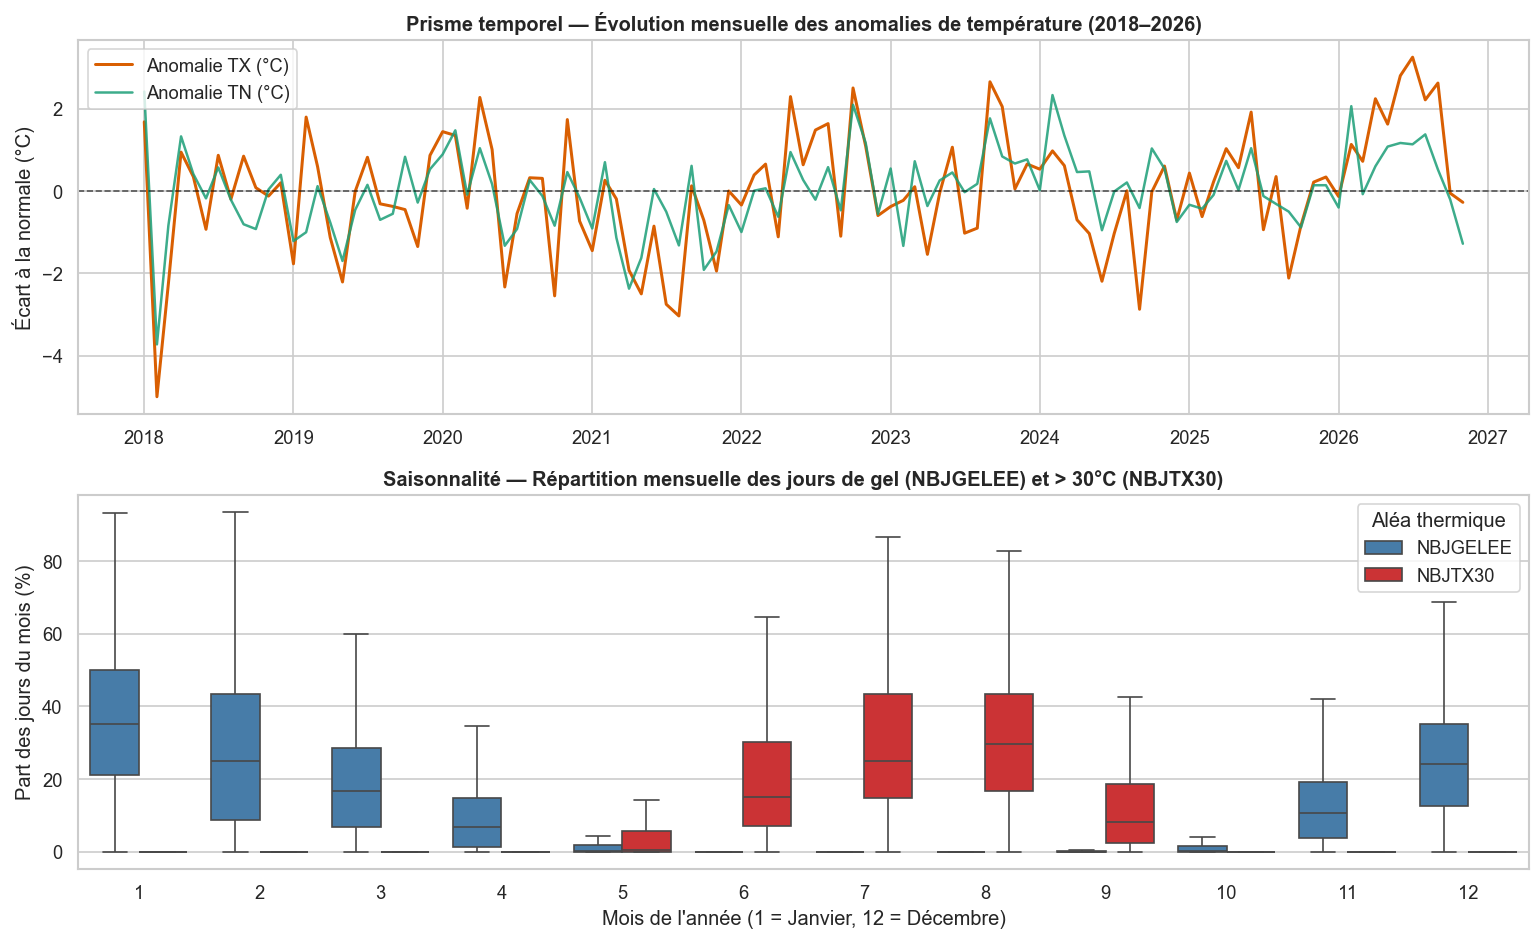

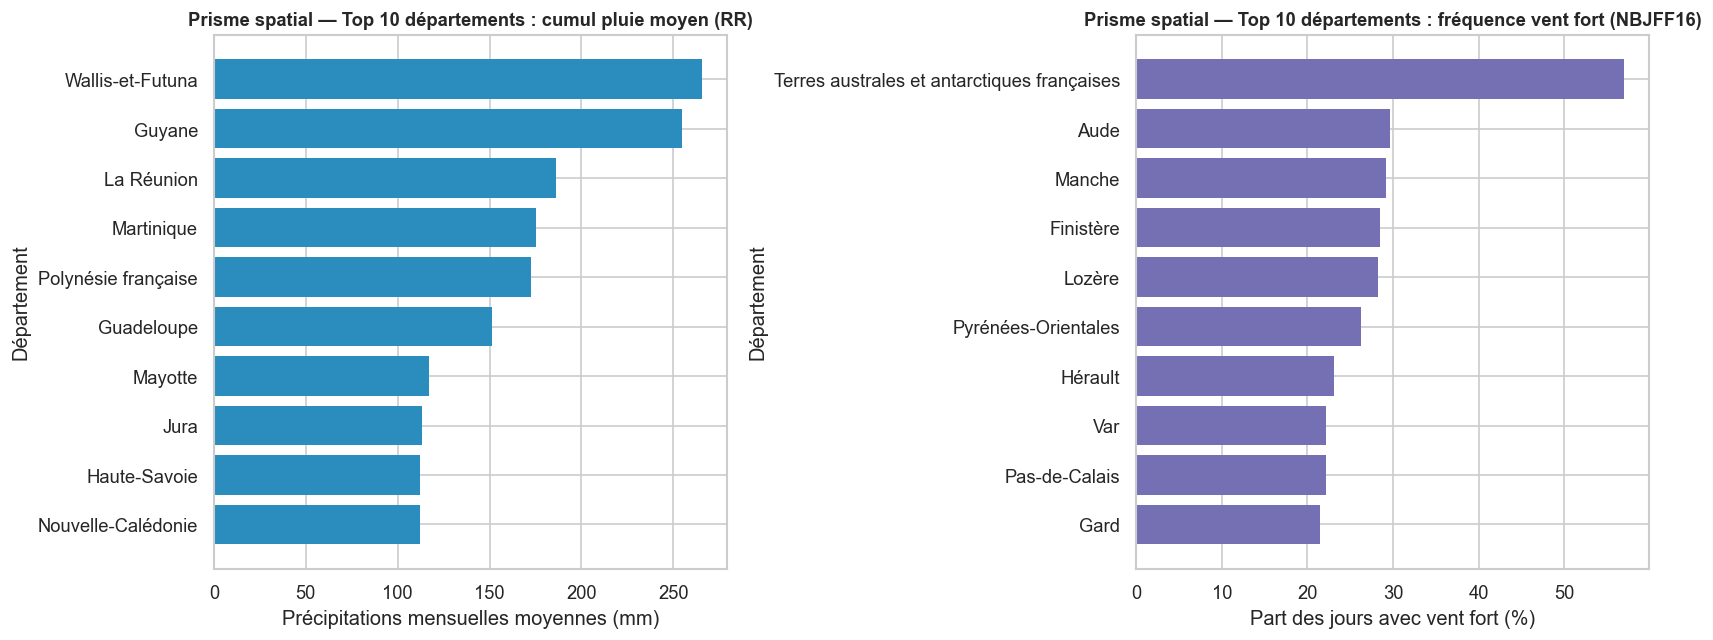

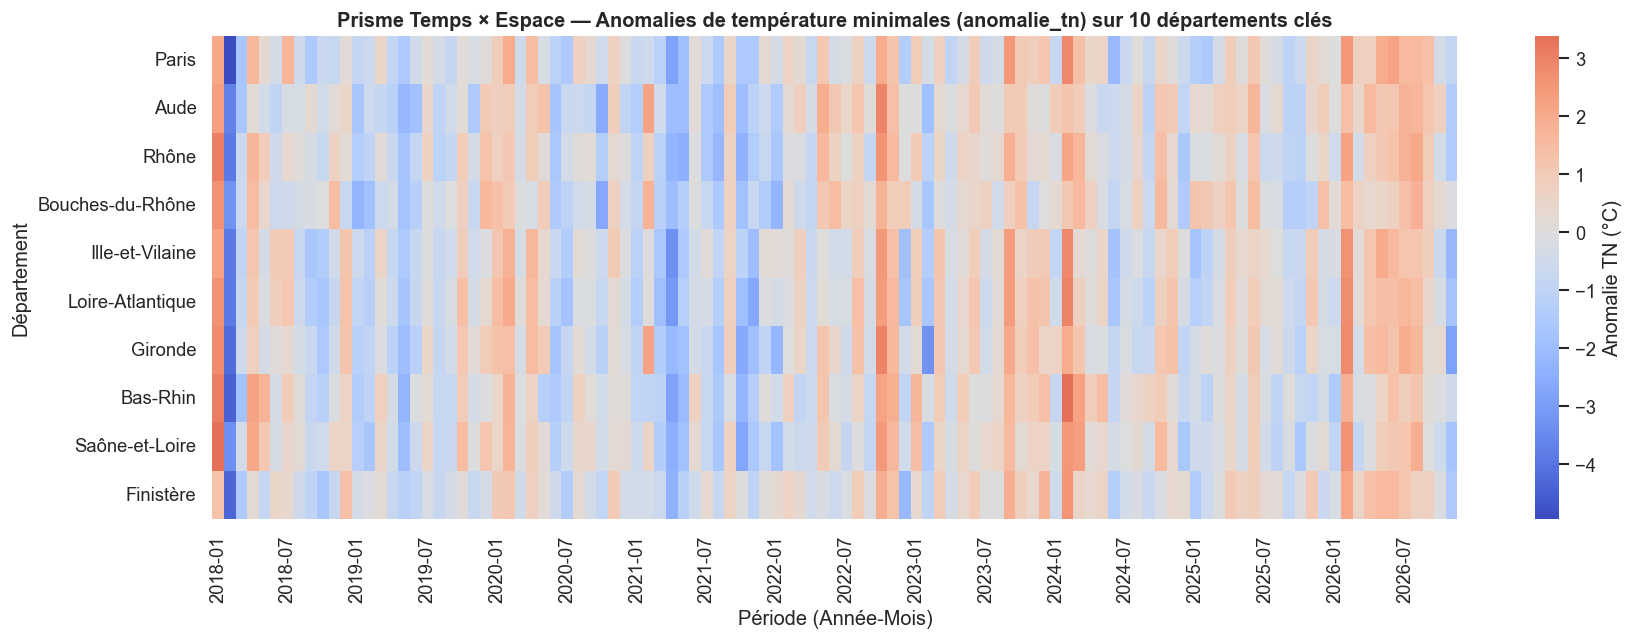

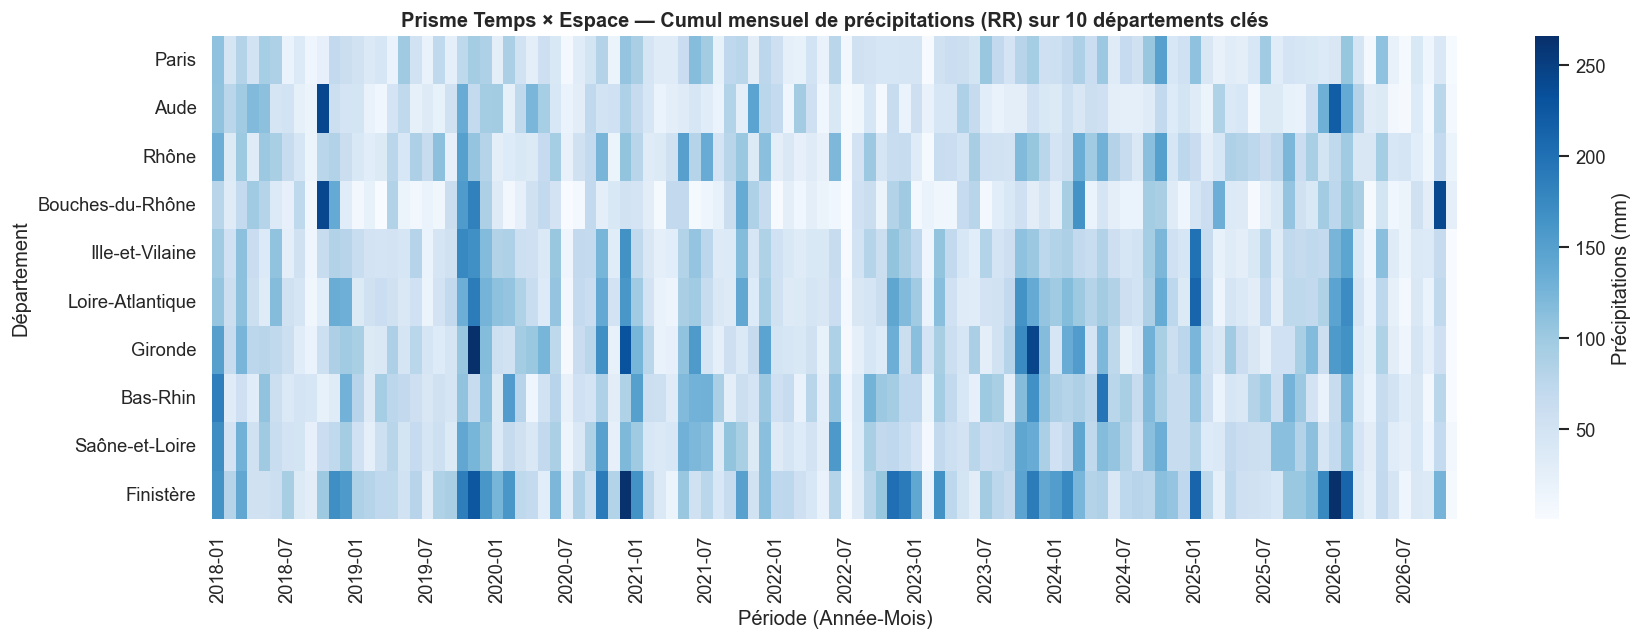

In [83]:
# Configuration esthétique générale pour harmoniser les graphiques
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# Préparation d'une copie de travail avec date datetime et département formaté
df_plot = df_meteo[df_meteo["DATE"] >= 201801].copy()
df_plot["dt"] = pd.to_datetime(df_plot["DATE"].astype(str), format="%Y%m")
df_plot["mois"] = df_plot["dt"].dt.month
df_plot["dep_str"] = df_plot["departement"].astype(str).str.zfill(2)
df_plot["dep_label"] = df_plot["NOM_DEP"].fillna(df_plot["dep_str"])

# ==============================================================================
# 1. PRISME TEMPOREL : Évolution mensuelle des anomalies & saisonnalité
# ==============================================================================
df_temporel = (
    df_plot.groupby("dt", as_index=False)[
        ["anomalie_tn", "anomalie_tx", "anomalie_rr_pct", "NBJGELEE", "NBJTX30"]
    ]
    .mean()
    .sort_values("dt")
)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=False)

# Graphique 1A : Anomalies thermiques mensuelles moyennes
axes[0].plot(
    df_temporel["dt"],
    df_temporel["anomalie_tx"],
    label="Anomalie TX (°C)",
    color="#d95f02",
    linewidth=1.8,
)
axes[0].plot(
    df_temporel["dt"],
    df_temporel["anomalie_tn"],
    label="Anomalie TN (°C)",
    color="#1b9e77",
    linewidth=1.5,
    alpha=0.85,
)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.6)
axes[0].set_title(
    "Prisme temporel — Évolution mensuelle des anomalies de température (2018–2026)",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_ylabel("Écart à la normale (°C)")
axes[0].legend(loc="upper left")

# Graphique 1B : Saisonnalité mensuelle des jours de gel vs forte chaleur (> 30°C)
df_saison = df_plot.melt(
    id_vars="mois",
    value_vars=["NBJGELEE", "NBJTX30"],
    var_name="Indicateur",
    value_name="Part_jours_pct",
)
sns.boxplot(
    data=df_saison,
    x="mois",
    y="Part_jours_pct",
    hue="Indicateur",
    palette={"NBJGELEE": "#377eb8", "NBJTX30": "#e41a1c"},
    ax=axes[1],
    showfliers=False,
)
axes[1].set_title(
    "Saisonnalité — Répartition mensuelle des jours de gel (NBJGELEE) et > 30°C (NBJTX30)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Mois de l'année (1 = Janvier, 12 = Décembre)")
axes[1].set_ylabel("Part des jours du mois (%)")
axes[1].legend(title="Aléa thermique")

plt.tight_layout()
plt.show()


# ======================================================================================
# 2. PRISME SPATIAL : Top 10 des départements les plus exposés aux aléas
# ======================================================================================
tracer_top_departements_meteo(df_meteo,indicateurs=("RR","NBJRR10"))

# ======================================================================================
# 3. PRISME CROISÉ (TEMPS × ESPACE) : Heatmap sur une sélection de départements
# ======================================================================================
# Les 10 Départements les plus présents dans la base SNCF
deps_cles = ["75", "11", "69", "13", "35", "44", "33", "67", "71", "29"]
tracer_heatmap_meteo(df_meteo, deps_cles, "anomalie_tn")
tracer_heatmap_meteo(df_meteo, deps_cles, "RR")

Prisme temporel (anomalies thermiques et saisonnalité) :   
- Les courbes d'anomalies (anomalie_tx et anomalie_tn) oscillent autour de 0 °C sur la période 2018–2026, avec des écarts ponctuels marqués (vagues de froid hivernales, comme début 2018 ou au printemps 2021, et épisodes chauds récurrents, notamment sur les années 2022 et 2026).   
- Les boxplots mensuels confirment une saisonnalité attendue : la part des jours de gel culmine de décembre à mars (avec des médianes atteignant environ 25 à 35 % en hiver et des pics élevés), tandis que les jours de forte chaleur se concentrent de juin à septembre avec un pic en juillet–août. De plus les mois de mai et octobre sont les mois les plus épargnés par ces phénomènes.

Prisme spatial (cumul de pluie et vent fort) :   
- Le classement des cumuls mensuels moyens de précipitations est dominé par les territoires d'outre-mer, aux côtés de départements métropolitains exposés au relief ou aux flux humides (Jura, Haute-Savoie).   
- Pour la fréquence des vents forts, un territoire des DROM se détache nettement en tête, suivi de départements métropolitains très exposés aux vents ou au relief/littoral (notamment l'Aude, la Manche, le Finistère, la Lozère).   
- Impact de la jointure avec la base SNCF : Les départements et collectivités d'outre-mer (DROM/COM) ne sont pas présents dans la base trafic SNCF ; ils seront donc naturellement exclus lors de la jointure avec les données ferroviaires. Les valeurs très élevées observées sur ces territoires (notamment en précipitations ou en vent) ne viendront donc pas fausser ni alourdir les analyses et modélisations ultérieures centrées sur le périmètre SNCF.

Prisme croisé Temps × Espace (heatmap d'anomalie_tx sur 10 départements clés) :   
- La carte de chaleur met en évidence une forte synchronisation temporelle des anomalies de température maximale entre ces départements clés (par exemple les épisodes froids marqués en bleu foncé début 2018 ou en 2021, et les séquences chaudes en rouge/orange, y compris en 2026), tout en laissant apparaître des nuances locales d'un mois à l'autre.   
- On repère également quelques cases blanches (valeurs manquantes ponctuelles, par exemple sur le département 59 en fin de période), qu'il conviendra d'avoir en tête lors de l'exploitation conjointe avec les données SNCF. 

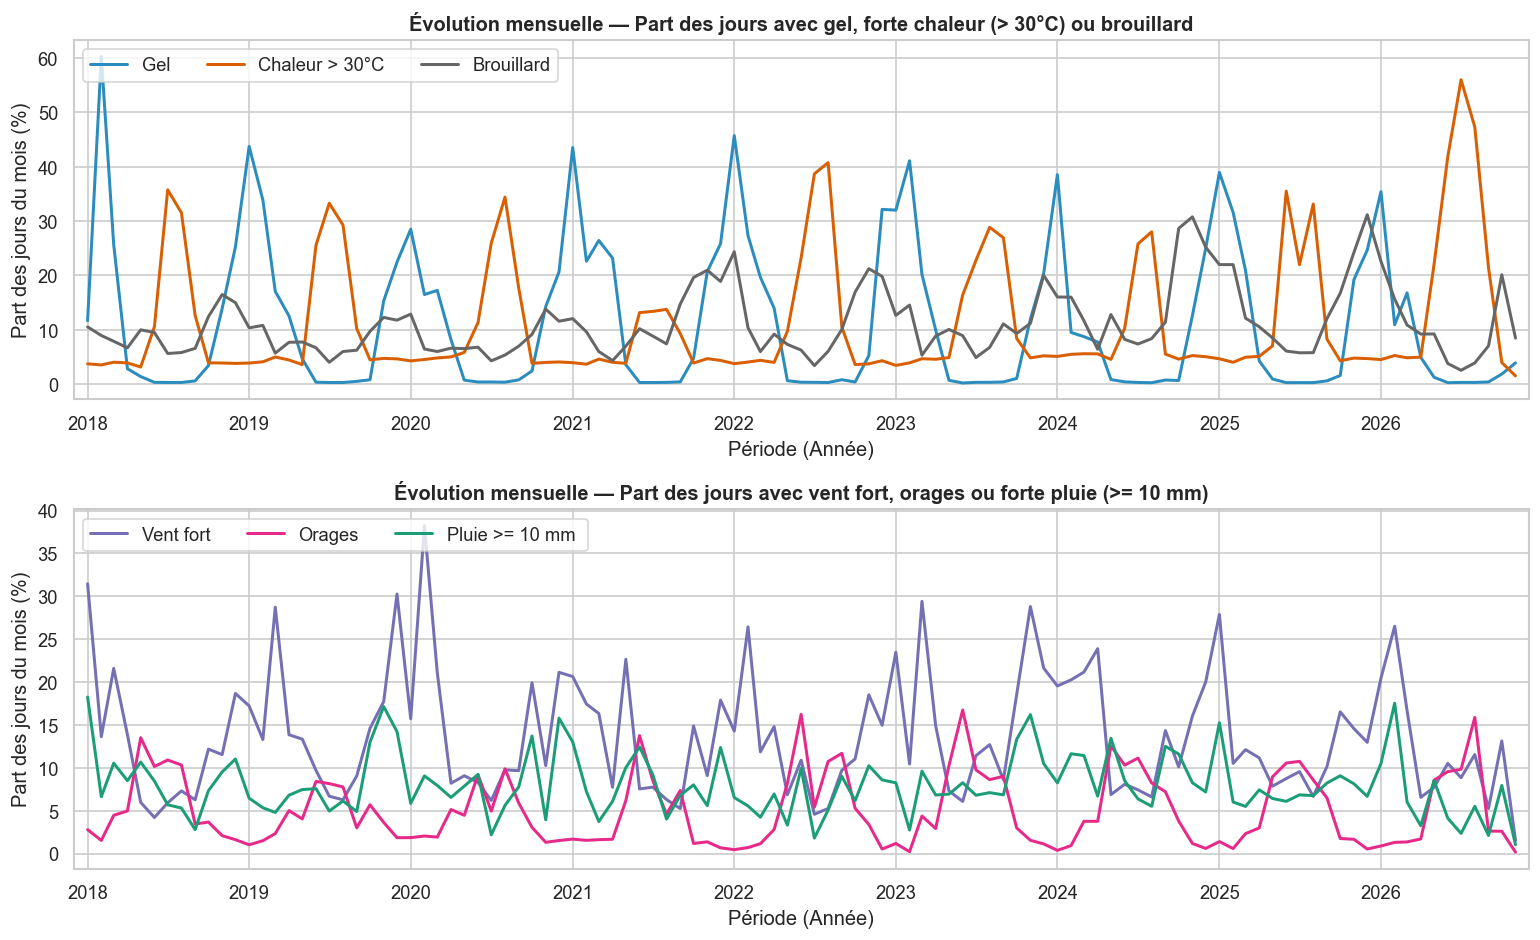

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# Préparation de la date mensuelle (à partir de janvier 2018)
df_nbj = df_meteo[df_meteo["DATE"] >= 201801].copy()
df_nbj["dt"] = pd.to_datetime(df_nbj["DATE"].astype(str), format="%Y%m")

# Sélection automatique des colonnes NBJ* existantes (hors neige si supprimée)
cols_nbj = [
    c for c in ["NBJGELEE", "NBJTX30", "NBJRR10", "NBJFF16", "NBJORAG", "NBJBROU"]
    if c in df_nbj.columns
]

# Moyenne mensuelle de chaque variable NBJ* sur l'ensemble des départements
df_nbj_mensuel = (
    df_nbj.groupby("dt", as_index=False)[cols_nbj].mean().sort_values("dt")
)

# Séparation en 2 panneaux pour éviter d'entasser trop de courbes sur un seul axe
groupe_1 = [c for c in ["NBJGELEE", "NBJTX30", "NBJBROU"] if c in cols_nbj]
groupe_2 = [c for c in ["NBJFF16", "NBJORAG","NBJRR10"] if c in cols_nbj]

labels_fr = {
    "NBJGELEE": "Gel",
    "NBJTX30": "Chaleur > 30°C",
    "NBJRR10": "Pluie >= 10 mm ",
    "NBJFF16": "Vent fort",
    "NBJORAG": "Orages",
    "NBJBROU": "Brouillard",
}

palette_fr = {
    "NBJGELEE": "#2b8cbe",
    "NBJTX30": "#d95f02",
    "NBJRR10": "#1b9e77",
    "NBJFF16": "#7570b3",
    "NBJORAG": "#e7298a",
    "NBJBROU": "#666666",
}

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=False)

# Panneau 1 : Gel, fortes chaleurs et brouillard
for col in groupe_1:
    axes[0].plot(
        df_nbj_mensuel["dt"],
        df_nbj_mensuel[col],
        label=labels_fr.get(col, col),
        color=palette_fr.get(col),
        linewidth=1.8,
    )
axes[0].set_title(
    "Évolution mensuelle — Part des jours avec gel, forte chaleur (> 30°C) ou brouillard",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Période (Année)")
axes[0].set_ylabel("Part des jours du mois (%)")
axes[0].legend(loc="upper left", ncol=3)
axes[0].set_xlim(pd.Timestamp("2017-12-01"), pd.Timestamp("2026-12-01"))

# Panneau 2 : Vent fort, orages et fortes pluies
for col in groupe_2:
    axes[1].plot(
        df_nbj_mensuel["dt"],
        df_nbj_mensuel[col],
        label=labels_fr.get(col, col),
        color=palette_fr.get(col),
        linewidth=1.8
    )
axes[1].set_title(
    "Évolution mensuelle — Part des jours avec vent fort, orages ou forte pluie (>= 10 mm)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Période (Année)")
axes[1].set_ylabel("Part des jours du mois (%)")
axes[1].legend(loc="upper left", ncol=3)
axes[1].set_xlim(pd.Timestamp("2017-12-01"), pd.Timestamp("2026-12-01"))

plt.tight_layout()
plt.show()

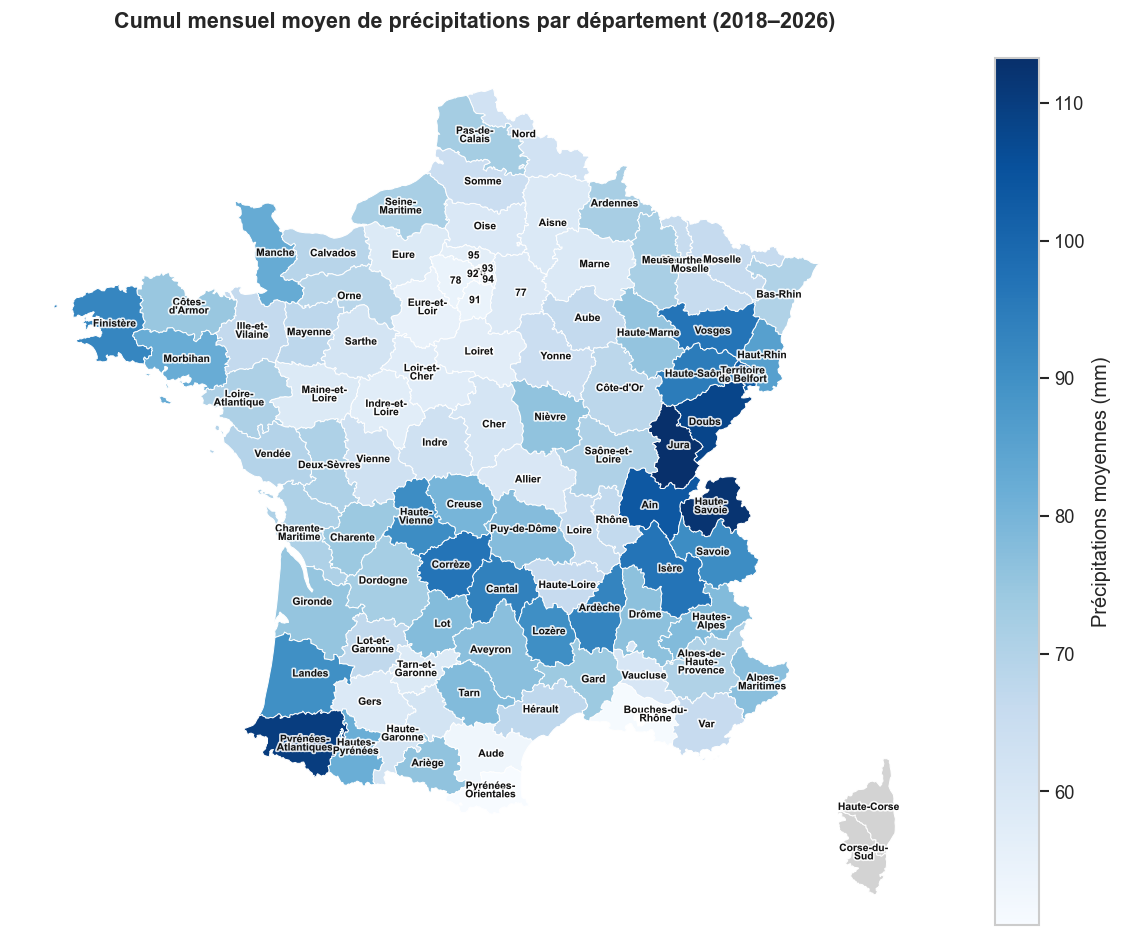

In [79]:
import f_stat_desc
import importlib
importlib.reload(f_stat_desc)
from f_stat_desc import tracer_carte_meteo
tracer_carte_meteo(df_meteo,"RR",labels="nom")


# 5. Jointure entre les données SNCF et Météo-France

Méthodologie de jointure entre les données SNCF et Météo-France
L'objectif de cette étape est d'enrichir chaque trajet SNCF avec les relevés météorologiques mensuels correspondants, aussi bien pour le département de départ que pour le département d'arrivée.

1. Préparation et harmonisation des clés de jointure
Pour qu'une fusion (merge) entre deux tables fonctionne sans perte d'information, les clés de correspondance doivent partager exactement le même format et le même type de données :

Harmonisation temporelle (annee_mois et DATE) : Dans la table SNCF, la date est initialement au format complet (YYYY-MM-DD). Nous la convertissons au format YYYYMM (ex. : 201801 pour janvier 2018) sous forme d'entier (int) afin qu'elle corresponde strictement à la colonne DATE de la table météo.

Normalisation des codes départements : Les codes départements sont convertis en chaînes de caractères (str) et formatés sur deux chiffres minimum via .zfill(2) (par exemple, '1' devient '01'). Cela évite les échecs de correspondance liés aux zéros initiaux manquants ou aux différences de types entre entiers et textes.

Arrondi des valeurs numériques : Les variables météo sont arrondies à l'entier le plus proche (0 décimale) et les indicateurs numériques SNCF à 1 décimale pour alléger et homogénéiser le jeu de données final.

2. Double jointure relationnelle (Départ puis Arrivée)
Un trajet reliant deux gares potentiellement situées dans des départements différents, la fusion s'effectue en deux étapes successives :

Suffixation préventive : Avant chaque jointure, l'ensemble des colonnes de df_meteo est renommé avec le suffixe _depart puis _arrivee (via .add_suffix()). Cela permet de distinguer clairement les conditions météo au point d'origine de celles à destination (ex. : RR_depart vs RR_arrivee pour les précipitations).

Jointure gauche (how='left') : Nous conservons l'intégralité des trajets de la table SNCF (df_sncf), même si une donnée météo venait à manquer pour un département ou un mois donné. La correspondance s'opère simultanément sur le code département et le mois (['dep_depart', 'annee_mois']).

Contrôle d'intégrité (validate='many_to_one') : Ce paramètre garantit qu'un couple (département, mois) est unique dans la table météo. Il permet de s'assurer qu'aucun trajet SNCF n'est dupliqué accidentellement lors de la fusion.

3. Nettoyage et exportation
Une fois les deux jointures réalisées, les colonnes techniques ayant servi uniquement à la liaison (departement_depart, DATE_depart, departement_arrivee, DATE_arrivee, annee_mois) sont supprimées pour éviter toute redondance. La base consolidée est ensuite enregistrée au format CSV (df_sncf_avec_meteo.csv) en encodage UTF-8.

In [ ]:
# Chargement des données
df_sncf = pd.read_csv("df_sncf_prepare.csv")

# On arrondit les variables numériques à 0 décimales après la virgule pour les données météo et 1 décimale pour les données sncf
df_meteo = df_meteo.round(0)
colonnes_numeriques = df_sncf.select_dtypes(include=['float64', 'float32']).columns
df_sncf[colonnes_numeriques] = df_sncf[colonnes_numeriques].round(1)

# Préparation de la clé de mois dans la base SNCF
# df_sncf['date'] est du type 'YYYY-MM-DD' -> on extrait l'année et le mois pour obtenir '201801' (en entier ou string)
df_sncf['annee_mois'] = pd.to_datetime(df_sncf['date']).dt.strftime('%Y%m').astype(int)

# S'assurer que le département météo et le département SNCF ont le même type (ex: string ou int)
df_meteo['departement'] = df_meteo['departement'].astype(str).str.zfill(2)
df_sncf['dep_depart'] = df_sncf['dep_depart'].astype(str).str.zfill(2)
df_sncf['dep_arrivee'] = df_sncf['dep_arrivee'].astype(str).str.zfill(2)
df_meteo['DATE'] = df_meteo['DATE'].astype(int)


# Première jointure : Météo du département de DÉPART
# On renomme toutes les colonnes météo entrantes avec le suffixe '_depart' pour les différencier
meteo_depart = df_meteo.add_suffix('_depart')
df_merged = pd.merge(
    df_sncf,
    meteo_depart,
    left_on=['dep_depart', 'annee_mois'],
    right_on=['departement_depart', 'DATE_depart'],
    how='left',
    validate='many_to_one'
)

# Seconde jointure : Météo du département d'ARRIVÉE
# On renomme toutes les colonnes météo entrantes avec le suffixe '_arrivee'
meteo_arrivee = df_meteo.add_suffix('_arrivee')
df_final = pd.merge(
    df_merged,
    meteo_arrivee,
    left_on=['dep_arrivee', 'annee_mois'],
    right_on=['departement_arrivee', 'DATE_arrivee'],
    how='left',
    validate='many_to_one'
)

# Nettoyage des colonnes de jointure en double si besoin
df_final = df_final.drop(columns=['departement_depart', 'DATE_depart', 'departement_arrivee', 'DATE_arrivee','annee_mois'])

# Aperçu du résultat
print(df_final[['date', 'gare_depart', 'dep_depart', 'RR_depart', 'gare_arrivee', 'dep_arrivee', 'RR_arrivee']].head())

# Sauvegarde du résultat final
df_final.to_csv("df_sncf_avec_meteo.csv", index=False, encoding="utf-8")